# Exercise 12 – Relaxing an atom with a zero-temperature Monte Carlo quench

**Week 3 · Monte Carlo and optimisation of clusters**

Atoms interact through the Lennard-Jones potential
$V(r) = 4\varepsilon[(\sigma/r)^{12} - (\sigma/r)^6]$ with
$\varepsilon = 5$ and $\sigma = 2^{-1/6}$, so the optimal bond length is 1.
Two atoms (orange) are held fixed and the third (blue) is moved by random
trial steps; at zero temperature only moves that lower the energy are
accepted. The path is drawn on top of the energy landscape felt by the
moving atom.

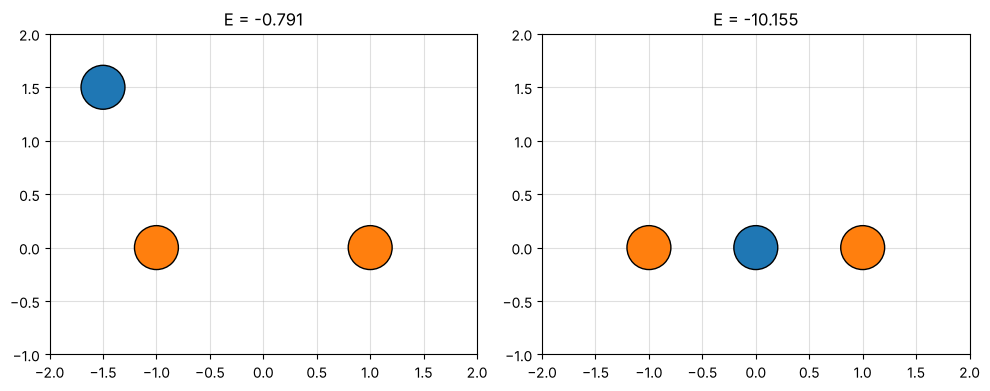

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from comphy.atoms import Cluster, LennardJones, energy_landscape, mc_quench

rng = np.random.default_rng(0)
calc = LennardJones()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pos in zip(axes, [[[-1, 0], [-1.5, 1.5], [1, 0]], [[-1, 0], [0, 0], [1, 0]]]):
    Cluster(calc, pos, static=[True, False, True]).draw(ax, size=1000)
    ax.set(xlim=(-2, 2), ylim=(-1, 2))
    ax.grid(True, alpha=0.4)
fig.tight_layout()
plt.show()

The configuration on the right – the middle atom exactly between the fixed
atoms, at distance 1 from both – is the minimum we expect to find.

37 accepted moves, final position [-0.0001 -0.0027], energy -10.1550


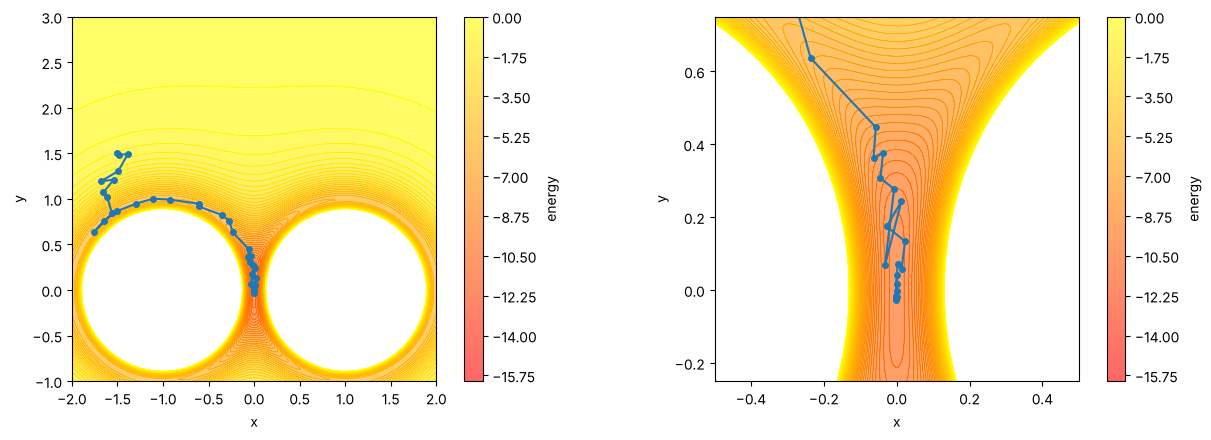

In [2]:
cluster = Cluster(calc, [[-1, 0], [-1.5, 1.5], [1, 0]], static=[True, False, True])
path = np.array(mc_quench(cluster, n_sweeps=10_000, step=0.15, rng=rng))
print(f"{len(path) - 1} accepted moves, final position {path[-1, 1].round(4)}, "
      f"energy {cluster.energy:.4f}")


def landscape_with_path(cluster, atom, path, views):
    fig, axes = plt.subplots(1, len(views), figsize=(6.5 * len(views), 4.5))
    for ax, (xlim, ylim) in zip(axes, views):
        xs, ys = np.linspace(*xlim, 150), np.linspace(*ylim, 150)
        Z = energy_landscape(cluster, atom, xs, ys)
        levels = np.arange(-16, 0.001, 0.25)
        filled = ax.contourf(xs, ys, Z, levels=levels, cmap="autumn", alpha=0.6)
        ax.contour(xs, ys, Z, levels=levels, cmap="autumn", linewidths=0.5)
        fig.colorbar(filled, ax=ax, label="energy")
        ax.plot(path[:, atom, 0], path[:, atom, 1], "o-", color="C0", ms=4)
        ax.set(xlim=xlim, ylim=ylim, aspect="equal", xlabel="x", ylabel="y")
    fig.tight_layout()
    plt.show()


landscape_with_path(cluster, 1, path, [((-2, 2), (-1, 3)), ((-0.5, 0.5), (-0.25, 0.75))])

The atom walks downhill into the valley and then along its floor to the
minimum between the fixed atoms (right: zoom). Because only downhill moves
are accepted, the steps get rarer as the minimum is approached.